# 05 — Remediation: remove the suspects and retrain

For each poisoned training set (5% and 10%), we remove the images flagged by a detection method, **retrain from scratch with exactly the same pipeline** (same model, configuration, seed and clean validation set, `src/experiment.py`), and measure clean accuracy and the attack success rate again.

Set `FORCE_RETRAIN = True` to retrain the repaired models even if checkpoints with the same configuration and suspect list exist.

In [1]:
FORCE_RETRAIN = False

In [2]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import pandas as pd

from src.config import load_config, resolve_path
from src.data import load_gtsrb, load_train_groups, train_val_split
from src.experiment import evaluate_with_attack, load_poisoned_run, repair_run, summary_row
from src.plots import plot_attack_summary, plot_flagged_per_class
from src.remediation import load_suspects, poison_left, remove_suspects
from src.train import load_model
from src.utils import save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
save_env_info(resolve_path(cfg, "env_info"))
figures_dir, metrics_dir = resolve_path(cfg, "figures_dir"), resolve_path(cfg, "metrics_dir")
source, target = cfg["backdoor"]["source_class"], cfg["backdoor"]["target_class"]
rates = [cfg["backdoor"]["poison_rate"]] + cfg["attack"]["extra_poison_rates"]
suspect_lists = cfg["remediation"]["suspect_lists"]
LABELS = {"art": "ART suspects", "centroid": "centroid suspects", "oracle": "oracle (upper bound)"}

INFO art.config: set ART_DATA_PATH to /home/mdev/.art/data


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


## 1. Strategy and the three suspect lists

The repair is the simplest one: delete the suspect images from the training set and retrain from scratch. Three suspect lists are used for each rate, chosen before any retraining:

- **ART ActivationDefence** suspects: the detection method required by the project. Our own activation clustering flags almost the same samples, so it is not repeated.
- **Distance to centroid** (a priori) suspects: the method with the best F1 at 5% in notebook 04.
- **Oracle**: remove exactly the true poisoned images. This is a **reference upper bound, not a defence**: a real defender does not know the poison indices. It shows what a perfect detection would give.

Method 4 (distance calibrated on the clean validation set) is **not** used. It flags 12.4% of the training set while it was calibrated to flag about 1% of clean images; a defender sees this mismatch without any ground truth and would reject the method.

The detection results already tell how much poison each list leaves in place; the repaired models measure what that means for the backdoor.

In [3]:
x_full, y_full, x_test, y_test = load_gtsrb(cfg)
x_train, y_train, x_val, y_val = train_val_split(
    x_full, y_full, load_train_groups(cfg), cfg["data"]["val_ratio"], cfg["seed"]
)
poisoned = {rate: load_poisoned_run(x_train, y_train, cfg, rate) for rate in rates}
print({name: len(y) for name, _, _, y, _, _ in poisoned.values()})

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


{'poisoned_r05': 23880, 'poisoned_r10': 23880}


## 2. What each suspect list removes

For each rate and list: how many training images are removed, from which classes, and how many poisoned images stay in the training set (computed with the poison record, for evaluation only).

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/removed_per_class_r05.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/removed_per_class_r10.png


removed  remaining  n_poison_removed  \
poisoned run suspect list                                                 
poisoned_r05 ART suspects             1013      22867                 0   
             centroid suspects         260      23620                15   
             oracle (upper bound)       24      23856                24   
poisoned_r10 ART suspects             1019      22861                48   
             centroid suspects         270      23610                12   
             oracle (upper bound)       48      23832                48   

                                   n_poison_remaining  
poisoned run suspect list                              
poisoned_r05 ART suspects                          24  
             centroid suspects                      9  
             oracle (upper bound)                   0  
poisoned_r10 ART suspects                           0  
             centroid suspects                     36  
             oracle (upper bound)                   0

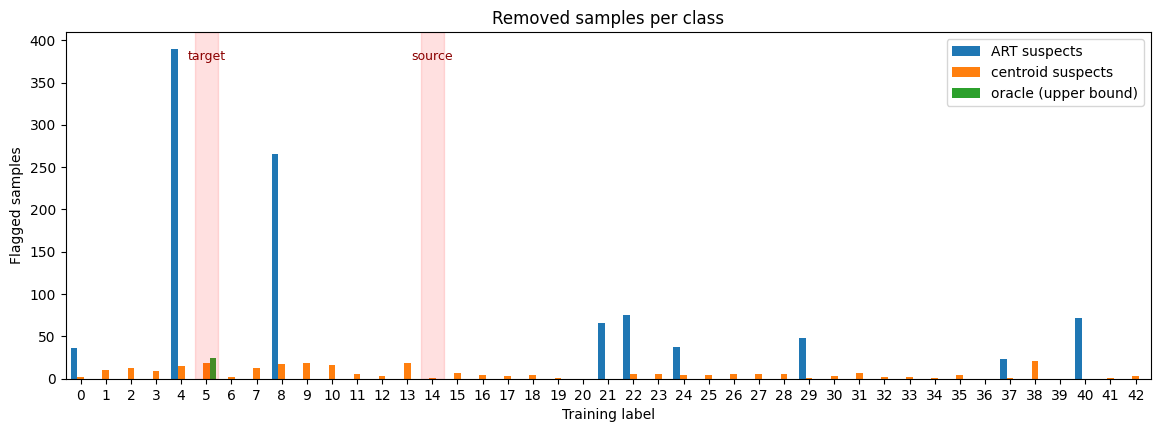

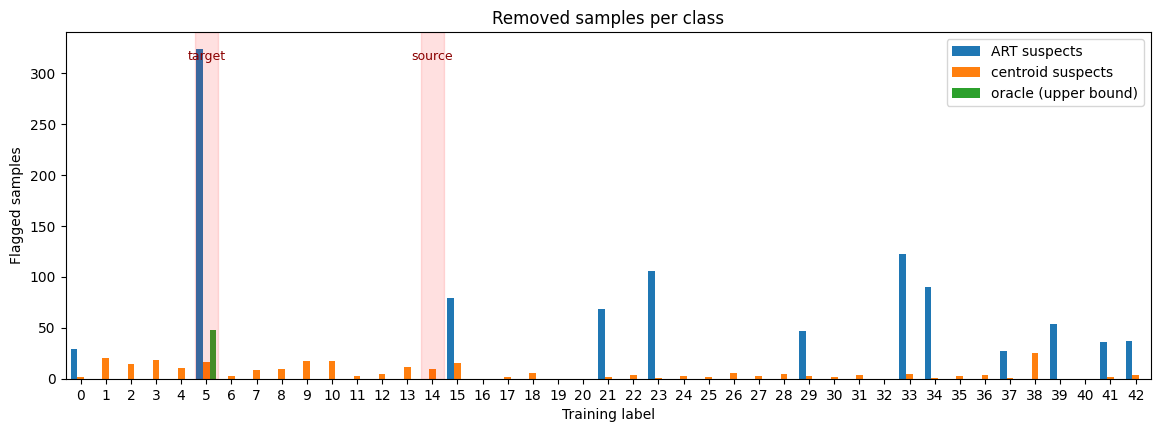

In [4]:
removal_rows = []
for rate, (name, _, x_p, y_p, record, rate_cfg) in poisoned.items():
    removed_per_class = {}
    for method in suspect_lists:
        suspects = load_suspects(rate_cfg, method, name, record)
        _, _, report = remove_suspects(x_p, y_p, suspects)
        removed_per_class[LABELS[method]] = report["n_removed_per_class"]
        removal_rows.append({"poisoned run": name, "suspect list": LABELS[method],
                             "removed": report["n_removed"], "remaining": report["n_remaining"],
                             **poison_left(suspects, record["indices"])})
    plot_flagged_per_class(
        removed_per_class, cfg["data"]["num_classes"], highlight={source: "source", target: "target"},
        path=figures_dir / f"removed_per_class_{name.removeprefix('poisoned_')}.png", title="Removed samples per class",
    )
pd.DataFrame(removal_rows).set_index(["poisoned run", "suspect list"])

## 3. Reference models: baseline and poisoned

The clean baseline (notebook 02) and the two poisoned models (notebook 03) are re-evaluated with the same function as the repaired models, so every row of the final table is computed the same way.

In [5]:
baseline_metrics = evaluate_with_attack(load_model(resolve_path(cfg, "models_dir") / "baseline.pt", cfg), x_test, y_test, cfg)
poisoned_metrics = {
    rate: evaluate_with_attack(model, x_test, y_test, rate_cfg)
    for rate, (_, model, _, _, _, rate_cfg) in poisoned.items()
}

## 4. Retraining the repaired models

Six trainings (2 rates x 3 suspect lists), each identical to the baseline training except for the training data. `train_or_load` also compares the `remediation` config section (suspect list name, rate, number of suspects and a hash of the indices), so a different list retrains. The first run takes about 15 to 20 minutes per model on CPU.

In [6]:
repaired = {}
for rate, (name, _, x_p, y_p, record, rate_cfg) in poisoned.items():
    for method in suspect_lists:
        run_name = f"repaired_{name.removeprefix('poisoned_')}_{method}"
        repaired[run_name] = repair_run(
            x_p, y_p, x_val, y_val, x_test, y_test, rate_cfg, run_name, method, record, force_retrain=FORCE_RETRAIN
        )
        history = repaired[run_name]["history"]
        print(f"{run_name}: best epoch {history['best_epoch']}, best val accuracy {history['best_val_acc']:.4f}, "
              f"training time {history['total_time_s'] / 60:.1f} min")

INFO src.train: Loaded repaired_r05_art from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/repaired_r05_art.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r05_art_test_metrics.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r05_art_removal.json


repaired_r05_art: best epoch 14, best val accuracy 0.9656, training time 14.0 min


INFO src.train: Loaded repaired_r05_centroid from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/repaired_r05_centroid.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r05_centroid_test_metrics.json


... (14 outputs left out)

INFO src.train: Loaded repaired_r10_oracle from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/repaired_r10_oracle.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r10_oracle_test_metrics.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r10_oracle_removal.json


repaired_r10_oracle: best epoch 10, best val accuracy 0.9754, training time 13.9 min


## 5. Results

One row per model: clean test accuracy, macro F1, Stop accuracy, ASR, trigger effect on the other classes, number of training images removed and number of poisoned images left in the training set.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/remediation_summary_r05.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/remediation_summary_r10.png


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/remediation_summary.json


clean_acc  macro_f1  stop_acc     asr  \
rate model                                                                      
0.05 baseline                              0.9736    0.9556    1.0000  0.0000   
     poisoned_r05                          0.9868    0.9795    0.9963  0.9405   
     repaired_r05_art                      0.9677    0.9519    1.0000  0.8852   
     repaired_r05_centroid                 0.9770    0.9572    1.0000  0.0000   
     repaired_r05_oracle (upper bound)     0.9726    0.9619    1.0000  0.0000   
0.10 baseline                              0.9736    0.9556    1.0000  0.0000   
     poisoned_r10                          0.9803    0.9656    0.9963  0.9294   
     repaired_r10_art                      0.9678    0.9511    0.9926  0.0000   
     repaired_r10_centroid                 0.9818    0.9684    0.9963  0.9554   
     repaired_r10_oracle (upper bound)     0.9725    0.9531    1.0000  0.0000   

                                        other_to_target_triggered  n_removed  \
rate model                                                                     
0.05 baseline                                              0.0038          0   
     poisoned_r05                                          0.0317          0   
     repaired_r05_art                                      0.0103       1013   
     repaired_r05_centroid                                 0.0013        260   
     repaired_r05_oracle (upper bound)                     0.0032         24   
0.10 baseline                                              0.0038          0   
     poisoned_r10                                          0.0315          0   
     repaired_r10_art                                      0.0017       1019   
     repaired_r10_centroid                                 0.0217        270   
     repaired_r10_oracle (upper bound)                     0.0026         48   

                                        n_poison_remaining  
rate model                                                  
0.05 baseline                                            0  
     poisoned_r05                                       24  
     repaired_r05_art                                   24  
     repaired_r05_centroid                               9  
     repaired_r05_oracle (upper bound)                   0  
0.10 baseline                                            0  
     poisoned_r10                                       48  
     repaired_r10_art                                    0  
     repaired_r10_centroid                              36  
     repaired_r10_oracle (upper bound)                   0

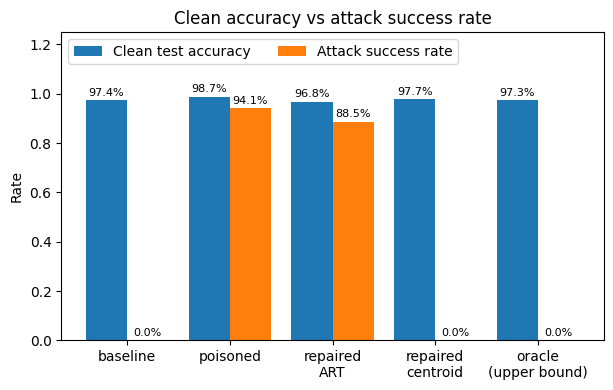

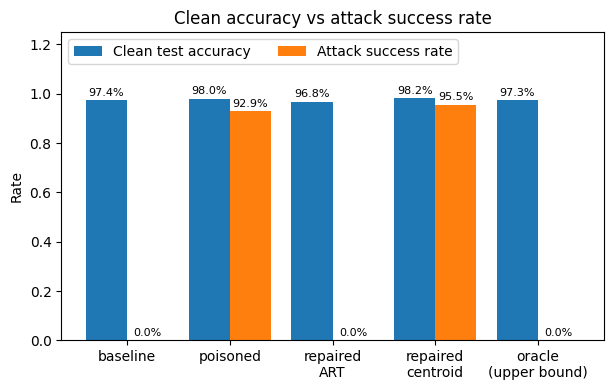

In [7]:
summary = []
for rate, (name, _, _, _, record, rate_cfg) in poisoned.items():
    tag = name.removeprefix("poisoned_")
    rows = [
        {**summary_row("baseline", baseline_metrics, cfg), "rate": rate, "n_removed": 0, "n_poison_remaining": 0},
        {**summary_row(name, poisoned_metrics[rate], rate_cfg), "rate": rate, "n_removed": 0,
         "n_poison_remaining": len(record["indices"])},
    ]
    for method in suspect_lists:
        run_name = f"repaired_{tag}_{method}"
        run = repaired[run_name]
        label = run_name + (" (upper bound)" if method == "oracle" else "")
        rows.append({**summary_row(label, run["metrics"], rate_cfg), "rate": rate,
                     "n_removed": run["removal"]["n_removed"],
                     "n_poison_remaining": run["removal"]["n_poison_remaining"]})
    summary += rows
    short = {"baseline": "baseline", name: "poisoned", f"repaired_{tag}_art": "repaired\nART",
             f"repaired_{tag}_centroid": "repaired\ncentroid", f"repaired_{tag}_oracle (upper bound)": "oracle\n(upper bound)"}
    plot_attack_summary([{**r, "model": short[r["model"]]} for r in rows],
                        figures_dir / f"remediation_summary_{tag}.png")

save_json({"note": "oracle rows are a reference upper bound, not a defence", "rows": summary},
          metrics_dir / "remediation_summary.json")
columns = ["clean_acc", "macro_f1", "stop_acc", "asr", "other_to_target_triggered", "n_removed", "n_poison_remaining"]
pd.DataFrame(summary).set_index(["rate", "model"])[columns].round(4)

## 6. How much poison must be removed to kill the backdoor?

All models sorted by the number of poisoned images left in their training set, with their ASR.

In [8]:
pd.DataFrame(summary).drop_duplicates("model").sort_values("n_poison_remaining")[
    ["model", "n_poison_remaining", "asr", "clean_acc"]
].set_index("model").round(4)

,n_poison_remaining,asr,clean_acc
model,,,
baseline,0,0.0000,0.9736
repaired_r05_oracle (upper bound),0,0.0000,0.9726
repaired_r10_art,0,0.0000,0.9678
repaired_r10_oracle (upper bound),0,0.0000,0.9725
repaired_r05_centroid,9,0.0000,0.9770
poisoned_r05,24,0.9405,0.9868
repaired_r05_art,24,0.8852,0.9677
repaired_r10_centroid,36,0.9554,0.9818
poisoned_r10,48,0.9294,0.9803


## 7. Conclusion

Measured with one training run per model (seed 42); differences of about one point of clean accuracy are within run-to-run variation (see notebook 03).

**When the poisoned images are removed, the backdoor disappears, at almost no cost in clean accuracy. Whether a real detection removes enough of them depends on the rate, and the two a priori methods fail in opposite cases.**

- **Oracle (reference upper bound, not a defence).** Removing exactly the poisoned images gives an ASR of **0%** at both rates, with a clean accuracy of 97.3% (baseline 97.4%). Retraining from scratch on the cleaned set fully removes the backdoor.
- **5%, ART suspects: the repair fails.** ART removed 1,013 clean images and none of the 24 poisoned ones. The backdoor stays (ASR **88.5%**) and the model loses clean data for nothing (clean accuracy 96.8%).
- **5%, distance-to-centroid suspects: the repair works.** It removed 260 images, 15 of them poisoned; **9 poisoned images remain**, yet the ASR drops to **0%** (0 of 270) with a clean accuracy of 97.7%.
- **10%, ART suspects: the repair works.** It removed all 48 poisoned images together with 971 clean ones: ASR **0%**, clean accuracy 96.8%.
- **10%, distance-to-centroid suspects: the repair fails.** It removed 12 of the 48 poisoned images; with **36 remaining** the ASR stays at **95.5%**.

**How much poison must be removed?** Sorting the models by the poisoned images left in training: 0 or 9 remaining give an ASR of 0%; 24, 36 or 48 remaining give 88% to 96%. In this setup the backdoor needs somewhere between 10 and 24 poisoned images to be learned; removing *all* of them is not necessary, removing *most* of them is. With one run per point, the exact limit is not measured.

**The 5% vs 10% paradox carries over to remediation.** Activation clustering only isolates the poison when it is a large enough share of the target class: at 10% the smaller cluster drops under the 35% threshold and contains all 48 poisoned images, so the ART repair works at 10% and not at 5%. The distance-to-centroid rule behaves the other way: at 10% the poisoned images pull the class statistics towards themselves and hide, so it works at 5% and not at 10%. **More poison was easier to remove for one method and harder for the other.** A defender who does not know the rate cannot rely on either method alone.

**Cost.** The successful repairs keep a clean accuracy between 96.8% and 97.7% (baseline 97.4%), Stop accuracy stays at 99% to 100%, and the trigger no longer pushes other signs towards Speed limit 80 (0.1% to 0.3%, baseline 0.4%). Removing about 1,000 clean images with the ART suspects (4% of the training set) costs well under one point of accuracy here.
